# 10 IMF DIP Production Development

## Purpose

This notebook develops the production treatment of IMF Direct Investment Positions (DIP) for the US–China Closeness Index.

It does **not** assume a final score formula. It first establishes:

1. the eligible project country universe for 2009–2024;
2. reproducible IMF-to-project country mapping;
3. the meaning and coverage of each reporting perspective;
4. the incremental coverage gained by candidate fallback hierarchies;
5. the incidence of missing, zero and negative positions;
6. the coverage consequences of one-way and two-way FDI formulations.

Notebook 09 established IMF DIP as the production source from 2009 onward. This notebook begins from that decision.

## Statistical object

For each project country, anchor and year, IMF DIP can represent two economic directions:

- **anchor to country**: the anchor owns a direct-investment asset in the country;
- **country to anchor**: the country owns a direct-investment asset in the anchor.

Each economic direction may be observed from either side. The economically preferred observation is the official outward position reported by the asset owner. A recipient-side inward report can be examined as a mirror fallback, but is not silently combined with the primary source.

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the project repository.")


PROJECT_ROOT = find_project_root()
IMF_PATH = PROJECT_ROOT / "data" / "interim" / "fdi" / "imf_dip_primary_candidates.csv"
COUNTRY_MASTER_PATH = PROJECT_ROOT / "outputs" / "tables" / "relations_condition" / "relationship_condition_country_master.csv"
RELATIONSHIP_CROSSWALK_PATH = PROJECT_ROOT / "outputs" / "tables" / "relations_condition" / "relationship_country_crosswalk_audit.csv"
SOURCE_ALIAS_PATH = PROJECT_ROOT / "outputs" / "tables" / "relations_condition" / "country_crosswalk_audit.csv"
BIT_CROSSWALK_PATH = PROJECT_ROOT / "outputs" / "tables" / "bilateral_investment_treaties" / "bit_counterparty_crosswalk.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "tables" / "fdi"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    IMF_PATH,
    COUNTRY_MASTER_PATH,
    RELATIONSHIP_CROSSWALK_PATH,
    SOURCE_ALIAS_PATH,
    BIT_CROSSWALK_PATH,
]
missing_paths = [p.relative_to(PROJECT_ROOT) for p in required_paths if not p.exists()]
if missing_paths:
    raise FileNotFoundError(f"Missing required repository inputs: {missing_paths}")

print("Project root: .")
for path in required_paths:
    print(path.relative_to(PROJECT_ROOT))
print(f"Output directory: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Project root: .
data/interim/fdi/imf_dip_primary_candidates.csv
outputs/tables/relations_condition/relationship_condition_country_master.csv
outputs/tables/relations_condition/relationship_country_crosswalk_audit.csv
outputs/tables/relations_condition/country_crosswalk_audit.csv
outputs/tables/bilateral_investment_treaties/bit_counterparty_crosswalk.csv
Output directory: outputs/tables/fdi


## 1. Load and validate the source tables

All five inputs use their established repository paths. The bilateral-investment-treaty crosswalk is a required mapping input because it contains reviewed counterparty aliases already produced by the project. The notebook fails early if any expected input is missing.


In [2]:
imf = pd.read_csv(IMF_PATH)
country_master = pd.read_csv(COUNTRY_MASTER_PATH)
relationship_crosswalk = pd.read_csv(RELATIONSHIP_CROSSWALK_PATH)
source_aliases = pd.read_csv(SOURCE_ALIAS_PATH)
bit_crosswalk = pd.read_csv(BIT_CROSSWALK_PATH)

required_imf = {
    "SERIES_CODE", "country_source_name", "anchor", "reporting_perspective",
    "economic_direction", "DV_TYPE", "DI_DIRECTION", "INSTR_ASSET", "DI_ENTITY",
    "ACCOUNTING_ENTRY", "UNIT", "year", "fdi_position_usd_millions", "observed",
    "negative", "zero",
}
required_master = {"iso3", "country_name", "historical_entity", "first_valid_year", "last_valid_year"}
assert required_imf.issubset(imf.columns), sorted(required_imf - set(imf.columns))
assert required_master.issubset(country_master.columns), sorted(required_master - set(country_master.columns))
assert not country_master["iso3"].duplicated().any()
assert country_master["iso3"].str.fullmatch(r"[A-Z]{3}", na=False).all()

print(f"IMF candidate rows: {len(imf):,}")
print(f"Country-master rows: {len(country_master):,}")
print(f"IMF years: {imf['year'].min()}–{imf['year'].max()}")

IMF candidate rows: 48,192
Country-master rows: 213
IMF years: 2009–2024


## 2. Define temporal eligibility

The common country master deliberately supports long-run indicators. Former states are retained in the library but are structurally ineligible for IMF DIP's 2009–2024 period.

`ESH` is not placed in the blanket historical exclusion set. The master label “Spanish Sahara” is historical, but modern IMF data may use “Western Sahara”; it is treated as a special territorial case and audited separately.

In [3]:
HISTORICAL_ENTITY_CODES = {
    "BYS", "CSK", "DDR", "DHY", "HVO", "RHO", "SCG", "SVU", "VDR", "YUG"
}
ANCHOR_ISO3 = {"China": "CHN", "United States": "USA"}

country_master = country_master.copy()
country_master["historically_ineligible_for_dip"] = country_master["iso3"].isin(HISTORICAL_ENTITY_CODES)
country_master["dip_period_eligible"] = ~country_master["historically_ineligible_for_dip"]

eligibility_audit = country_master.loc[
    country_master["historically_ineligible_for_dip"]
].sort_values("iso3")

print(f"Eligible master entities before anchor-self exclusions: {country_master['dip_period_eligible'].sum():,}")
eligibility_audit

Eligible master entities before anchor-self exclusions: 203


,iso3,country_name,historical_entity,first_valid_year,last_valid_year,historically_ineligible_for_dip,dip_period_eligible
28,BYS,Byelorussian SSR,False,NaN,NaN,True,False
43,CSK,Czechoslovakia,False,NaN,NaN,True,False
47,DDR,German Democratic Republic,False,NaN,NaN,True,False
49,DHY,Dahomey,False,NaN,NaN,True,False
84,HVO,Upper Volta,False,NaN,NaN,True,False
158,RHO,Rhodesia,False,NaN,NaN,True,False
163,SCG,Serbia and Montenegro,True,2000.0,2006.0,True,False
178,SVU,Soviet Union,False,NaN,NaN,True,False
203,VDR,North Vietnam,False,NaN,NaN,True,False
209,YUG,Yugoslavia,False,NaN,NaN,True,False


## 3. Build and classify the IMF-to-project country crosswalk

Mapping is restricted to the established project master. Reviewed aliases resolve IMF legal-form names for project entities. All remaining IMF names are explicitly classified as regional/global aggregates, confidentiality categories, or territories outside the project master. No fuzzy match is accepted automatically.

In [4]:
def normalise_name(value: object) -> str:
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode().lower()
    text = text.replace("&", " and ")
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text).split())

mapping_rows=[]
for row in country_master.itertuples(index=False):
    mapping_rows.append((normalise_name(row.country_name), row.iso3, "country_master"))
for row in relationship_crosswalk.itertuples(index=False):
    mapping_rows.append((normalise_name(row.drd_country_name), row.country, "relationship_crosswalk"))
for row in source_aliases.itertuples(index=False):
    mapping_rows.append((normalise_name(row.source_name), row.iso3, "source_alias_audit"))
for row in bit_crosswalk.itertuples(index=False):
    mapping_rows.append((
        normalise_name(row.counterparty_source_name),
        row.country_iso3,
        "bit_crosswalk",
    ))

mapping_evidence=pd.DataFrame(mapping_rows,columns=["normalised_name","iso3","mapping_source"]).dropna()
ambiguous=set(mapping_evidence.groupby("normalised_name")["iso3"].nunique().loc[lambda s:s>1].index)
project_lookup=(mapping_evidence.loc[~mapping_evidence["normalised_name"].isin(ambiguous)]
                .drop_duplicates("normalised_name").set_index("normalised_name")["iso3"].to_dict())

manual_aliases={
 "hong kong special administrative region people s republic of china":"HKG",
 "netherlands the":"NLD", "kyrgyz republic":"KGZ", "eswatini kingdom of":"SWZ",
 "eritrea the state of":"ERI", "naoero republic of":"NRU",
 "st vincent and the grenadines":"VCT", "st kitts and nevis":"KNA", "st lucia":"LCA",
 "marshall islands republic of the":"MHL", "ethiopia the federal democratic republic of":"ETH",
 "bahamas the":"BHS", "china people s republic of":"CHN", "egypt arab republic of":"EGY",
 "gambia the":"GMB", "iran islamic republic of":"IRN", "korea republic of":"KOR",
 "lao people s democratic republic":"LAO", "moldova republic of":"MDA",
 "russian federation":"RUS", "syrian arab republic":"SYR", "taiwan province of china":"TWN",
 "tanzania united republic of":"TZA", "timor leste democratic republic of":"TLS",
 "turkiye republic of":"TUR", "venezuela republica bolivariana de":"VEN",
 "west bank and gaza":"PSE", "western sahara":"ESH", "yemen republic of":"YEM",
}
aggregate_names={normalise_name(x) for x in [
 "World","North and Central America","South America","East Asia","Sub-Saharan Africa",
 "Central and South Asia","Economies of Persian Gulf","Oceania and Polar Regions",
 "Other Near and Middle East Economies","Europe","North Atlantic and Caribbean","North Africa"]}
confidential_names={normalise_name("Not Specified (including Confidential)")}

rows=[]
for source_name in sorted(imf["country_source_name"].dropna().unique()):
    key=normalise_name(source_name)
    if key in manual_aliases:
        iso3,method=manual_aliases[key],"reviewed_alias"
    elif key in project_lookup:
        iso3,method=project_lookup[key],"normalised_exact"
    else:
        iso3,method=pd.NA,"unresolved"
    if pd.notna(iso3): category="project_entity"
    elif key in aggregate_names: category="aggregate"
    elif key in confidential_names: category="not_specified_or_confidential"
    else: category="territory_or_entity_outside_project_master"
    rows.append({"country_source_name":source_name,"normalised_name":key,"country_iso3":iso3,
                 "mapping_method":method,"entity_category":category})

imf_country_crosswalk=(pd.DataFrame(rows).merge(
    country_master[["iso3","country_name","dip_period_eligible"]],
    left_on="country_iso3",right_on="iso3",how="left",validate="many_to_one").drop(columns="iso3"))

assert set(imf_country_crosswalk.loc[imf_country_crosswalk.entity_category.eq("project_entity"),"country_iso3"]) <= set(country_master.iso3)
imf_country_crosswalk.groupby(["entity_category","mapping_method"],dropna=False).size().rename("names").reset_index()

,entity_category,mapping_method,names
0,aggregate,unresolved,12
1,not_specified_or_confidential,unresolved,1
2,project_entity,normalised_exact,141
3,project_entity,reviewed_alias,29
4,territory_or_entity_outside_project_master,unresolved,76


In [5]:
name_observations=(imf.loc[imf["observed"]].groupby("country_source_name",as_index=False)
                   .agg(observed_values=("year","size"),first_year=("year","min"),last_year=("year","max")))
name_classification_audit=(imf_country_crosswalk.merge(name_observations,on="country_source_name",how="left")
                           .sort_values(["entity_category","observed_values","country_source_name"],ascending=[True,False,True]))
print(f"Mapped project entities: {imf_country_crosswalk['country_iso3'].notna().sum():,}")
print(f"Non-project IMF names retained in audit: {imf_country_crosswalk['country_iso3'].isna().sum():,}")
name_classification_audit.loc[name_classification_audit.entity_category.ne("project_entity")].head(50)

Mapped project entities: 170
Non-project IMF names retained in audit: 89


,country_source_name,normalised_name,country_iso3,mapping_method,entity_category,country_name,dip_period_eligible,observed_values,first_year,last_year
255,World,world,<NA>,unresolved,aggregate,NaN,NaN,238,2009,2024
172,North and Central America,north and central america,<NA>,unresolved,aggregate,NaN,NaN,212,2009,2024
209,South America,south america,<NA>,unresolved,aggregate,NaN,NaN,208,2009,2024
64,East Asia,east asia,<NA>,unresolved,aggregate,NaN,NaN,198,2009,2024
219,Sub-Saharan Africa,sub saharan africa,<NA>,unresolved,aggregate,NaN,NaN,196,2009,2024
42,Central and South Asia,central and south asia,<NA>,unresolved,aggregate,NaN,NaN,184,2009,2024
65,Economies of Persian Gulf,economies of persian gulf,<NA>,unresolved,aggregate,NaN,NaN,182,2009,2024
176,Oceania and Polar Regions,oceania and polar regions,<NA>,unresolved,aggregate,NaN,NaN,180,2009,2024
178,Other Near and Middle East Economies,other near and middle east economies,<NA>,unresolved,aggregate,NaN,NaN,178,2009,2024
74,Europe,europe,<NA>,unresolved,aggregate,NaN,NaN,176,2009,2024


## 4. Attach project identifiers and define the eligible IMF panel

Coverage is calculated against project entities only. Historically ineligible entities and anchor self-relations are excluded. Aggregates, confidentiality categories and out-of-master territories remain in the mapping audit but never enter the denominator.

In [6]:
imf_mapped=imf.merge(imf_country_crosswalk[["country_source_name","country_iso3","country_name","mapping_method","entity_category","dip_period_eligible"]],on="country_source_name",how="left",validate="many_to_one")
imf_mapped["anchor_iso3"]=imf_mapped["anchor"].map(ANCHOR_ISO3)
imf_mapped["anchor_self_relation"]=(imf_mapped["country_iso3"].fillna("__MISSING_COUNTRY__").astype(str)==imf_mapped["anchor_iso3"].fillna("__MISSING_ANCHOR__").astype(str))
dip_eligible=imf_mapped["dip_period_eligible"].astype("boolean").fillna(False)
imf_mapped["production_eligible"]=imf_mapped["country_iso3"].notna() & dip_eligible & ~imf_mapped["anchor_self_relation"]
unexpected=imf_mapped.loc[imf_mapped["observed"] & imf_mapped["country_iso3"].isin(HISTORICAL_ENTITY_CODES)]
assert unexpected.empty
imf_mapped.groupby(["entity_category","production_eligible","observed"],dropna=False).size().rename("rows").reset_index()

,entity_category,production_eligible,observed,rows
0,aggregate,False,False,782
1,aggregate,False,True,2290
2,not_specified_or_confidential,False,False,26
3,not_specified_or_confidential,False,True,102
4,project_entity,False,False,18
5,project_entity,False,True,110
6,project_entity,True,False,7078
7,project_entity,True,True,25498
8,territory_or_entity_outside_project_master,False,False,4184
9,territory_or_entity_outside_project_master,False,True,8104


## 5. Audit IMF metadata representations

The earlier run treated `Derived using counterparty information` as an independent mirror fallback. The extracted candidates show otherwise: for the same project key, the derived representation duplicates the official value and adds no coverage. This section tests that relationship explicitly. Production analysis therefore uses only the asset owner's reported official outward position.

In [7]:
def representation_role(frame):
    official=(((frame.economic_direction.eq("anchor_to_country") & frame.reporting_perspective.eq("anchor_report")) |
               (frame.economic_direction.eq("country_to_anchor") & frame.reporting_perspective.eq("country_report"))) &
              frame.DV_TYPE.eq("Reported official data"))
    duplicate=(((frame.economic_direction.eq("anchor_to_country") & frame.reporting_perspective.eq("country_report")) |
                (frame.economic_direction.eq("country_to_anchor") & frame.reporting_perspective.eq("anchor_report"))) &
               frame.DV_TYPE.eq("Derived using counterparty information"))
    return pd.Series(np.select([official,duplicate],["official_asset_owner","derived_duplicate_representation"],default="other"),index=frame.index)

imf_mapped["representation_role"]=representation_role(imf_mapped)
rep=imf_mapped.loc[imf_mapped.production_eligible & imf_mapped.representation_role.ne("other")].copy()
KEYS=["country_iso3","anchor","year","economic_direction"]
rep_wide=rep.pivot_table(index=KEYS,columns="representation_role",values="fdi_position_usd_millions",aggfunc="first",dropna=False).reset_index()
for col in ["official_asset_owner","derived_duplicate_representation"]:
    if col not in rep_wide: rep_wide[col]=np.nan
paired_mask=rep_wide[["official_asset_owner","derived_duplicate_representation"]].notna().all(axis=1)
metadata_representation_audit=pd.DataFrame({
 "official_observed":[rep_wide.official_asset_owner.notna().sum()],
 "derived_observed":[rep_wide.derived_duplicate_representation.notna().sum()],
 "paired_observed":[paired_mask.sum()],
 "derived_only":[(rep_wide.official_asset_owner.isna() & rep_wide.derived_duplicate_representation.notna()).sum()],
 "nonidentical_paired":[(~np.isclose(rep_wide.loc[paired_mask,"official_asset_owner"],rep_wide.loc[paired_mask,"derived_duplicate_representation"],equal_nan=True)).sum()],
})
metadata_representation_audit

,official_observed,derived_observed,paired_observed,derived_only,nonidentical_paired
0,5191,5191,5191,0,0


## 6. Official asset-owner coverage by year

In [8]:
official=rep.loc[rep.representation_role.eq("official_asset_owner")].copy()
assert not official.duplicated(KEYS).any()
# Construct the full eligible project grid so absent IMF rows remain missing rather than disappearing.
eligible_codes=country_master.loc[country_master.dip_period_eligible,"iso3"]
grid=pd.MultiIndex.from_product([eligible_codes,["China","United States"],range(2009,2025),["anchor_to_country","country_to_anchor"]],names=KEYS).to_frame(index=False)
grid=grid.loc[~((grid.anchor.eq("China") & grid.country_iso3.eq("CHN")) | (grid.anchor.eq("United States") & grid.country_iso3.eq("USA")))].copy()
official_panel=grid.merge(official[KEYS+["fdi_position_usd_millions"]],on=KEYS,how="left",validate="one_to_one")
official_panel=official_panel.rename(columns={"fdi_position_usd_millions":"official_value_usd_mn"})
coverage_by_year=(official_panel.groupby(["year","anchor","economic_direction"],as_index=False)
                  .agg(eligible_keys=("country_iso3","size"),observed_keys=("official_value_usd_mn","count")))
coverage_by_year["coverage_pct"]=100*coverage_by_year.observed_keys/coverage_by_year.eligible_keys
coverage_by_year.tail(12)

,year,anchor,economic_direction,eligible_keys,observed_keys,coverage_pct
52,2022,China,anchor_to_country,202,168,83.168317
53,2022,China,country_to_anchor,202,58,28.712871
54,2022,United States,anchor_to_country,202,139,68.811881
55,2022,United States,country_to_anchor,202,65,32.178218
56,2023,China,anchor_to_country,202,168,83.168317
57,2023,China,country_to_anchor,202,55,27.227723
58,2023,United States,anchor_to_country,202,141,69.801980
59,2023,United States,country_to_anchor,202,62,30.693069
60,2024,China,anchor_to_country,202,168,83.168317
61,2024,China,country_to_anchor,202,51,25.247525


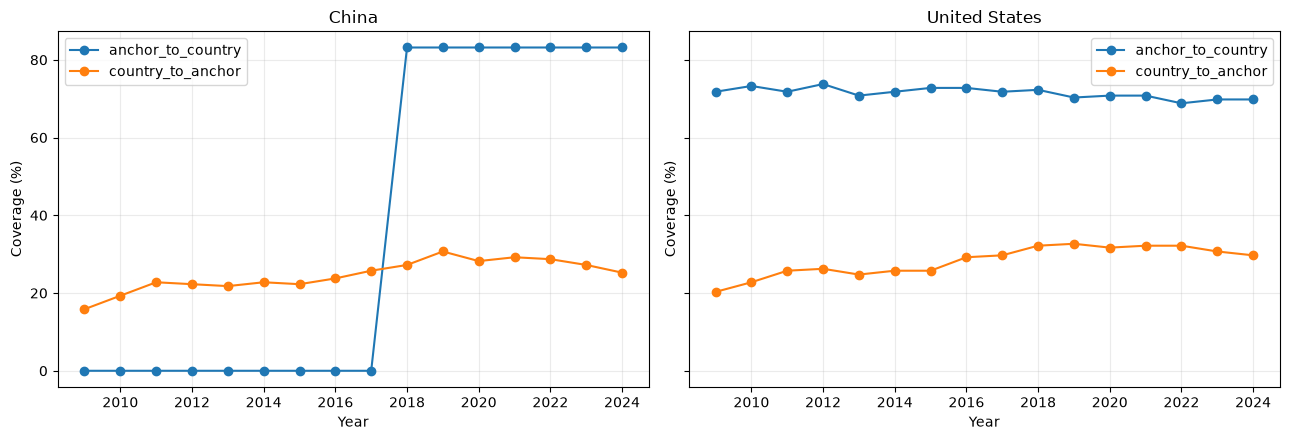

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),sharex=True,sharey=True)
for ax,(anchor,g) in zip(axes,coverage_by_year.groupby("anchor")):
    for direction,s in g.groupby("economic_direction"):
        ax.plot(s.year,s.coverage_pct,marker="o",label=direction)
    ax.set_title(anchor); ax.set_xlabel("Year"); ax.set_ylabel("Coverage (%)"); ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.show()

## 7. Zeros, negatives and missingness

Observed zeros and negative net positions are preserved. Missing values are not converted to zero. No truncation or absolute-value transformation is applied in this development notebook.

In [10]:
value_audit=(official_panel.groupby(["anchor","economic_direction"],as_index=False)
 .agg(eligible=("country_iso3","size"),observed=("official_value_usd_mn","count"),
      zero=("official_value_usd_mn",lambda s:s.eq(0).sum()),negative=("official_value_usd_mn",lambda s:s.lt(0).sum()),
      positive=("official_value_usd_mn",lambda s:s.gt(0).sum()),minimum_usd_mn=("official_value_usd_mn","min"),
      median_usd_mn=("official_value_usd_mn","median"),maximum_usd_mn=("official_value_usd_mn","max")))
value_audit["missing"]=value_audit.eligible-value_audit.observed
value_audit

,anchor,economic_direction,eligible,observed,zero,negative,positive,minimum_usd_mn,median_usd_mn,maximum_usd_mn,missing
0,China,anchor_to_country,3232,1176,99,0,1077,0.00000,307.863650,1.920809e+06,2056
1,China,country_to_anchor,3232,794,110,9,675,-328.78740,420.288949,1.134814e+06,2438
2,United States,anchor_to_country,3232,2309,340,95,1874,-21251.00000,548.000000,1.041247e+06,923
3,United States,country_to_anchor,3232,912,68,18,826,-31892.21714,5260.655265,1.084187e+06,2320


## 8. Compare outward-footprint and complete two-way coverage

This is a coverage comparison only. `outward_footprint_available` requires anchor-to-country data. `two_way_complete` requires both economic directions for the same project country, anchor and year.

In [11]:
paired=official_panel.pivot(index=["country_iso3","anchor","year"],columns="economic_direction",values="official_value_usd_mn").reset_index()
for col in ["anchor_to_country","country_to_anchor"]:
    if col not in paired: paired[col]=np.nan
paired["outward_footprint_available"]=paired.anchor_to_country.notna()
paired["two_way_complete"]=paired[["anchor_to_country","country_to_anchor"]].notna().all(axis=1)
paired["at_least_one_direction"]=paired[["anchor_to_country","country_to_anchor"]].notna().any(axis=1)
formulation_coverage=(paired.groupby(["year","anchor"],as_index=False)
 .agg(eligible_country_rows=("country_iso3","size"),outward_footprint_available=("outward_footprint_available","sum"),
      two_way_complete=("two_way_complete","sum"),at_least_one_direction=("at_least_one_direction","sum")))
for col in ["outward_footprint_available","two_way_complete","at_least_one_direction"]:
    formulation_coverage[f"{col}_pct"]=100*formulation_coverage[col]/formulation_coverage.eligible_country_rows
formulation_coverage.tail(12)

,year,anchor,eligible_country_rows,outward_footprint_available,two_way_complete,at_least_one_direction,outward_footprint_available_pct,two_way_complete_pct,at_least_one_direction_pct
20,2019,China,202,168,62,168,83.168317,30.693069,83.168317
21,2019,United States,202,142,62,146,70.297030,30.693069,72.277228
22,2020,China,202,168,57,168,83.168317,28.217822,83.168317
23,2020,United States,202,143,61,146,70.792079,30.198020,72.277228
24,2021,China,202,168,59,168,83.168317,29.207921,83.168317
25,2021,United States,202,143,64,144,70.792079,31.683168,71.287129
26,2022,China,202,168,58,168,83.168317,28.712871,83.168317
27,2022,United States,202,139,64,140,68.811881,31.683168,69.306931
28,2023,China,202,168,55,168,83.168317,27.227723,83.168317
29,2023,United States,202,141,62,141,69.801980,30.693069,69.801980


## 9. Revised development conclusions

- The derived IMF rows are duplicate metadata representations, not an independent fallback source.
- Production development should proceed using official asset-owner outward positions only.
- Reviewed aliases now map project entities that were previously missed, including Hong Kong, the Netherlands, Kyrgyzstan, Eswatini, Eritrea, Nauru, the Marshall Islands, Ethiopia and three Caribbean states.
- IMF aggregates, confidentiality categories and territories outside the project master are classified and excluded from the project denominator.
- The remaining decisions concern one-way versus two-way formulation, the production window, treatment of negative net positions and normalization. No score is selected here.

## 10. Export compact revised audits

In [12]:
exports={
 "imf_dip_country_crosswalk_audit.csv":imf_country_crosswalk,
 "imf_dip_name_classification_audit.csv":name_classification_audit,
 "imf_dip_metadata_representation_audit.csv":metadata_representation_audit,
 "imf_dip_official_coverage_by_year.csv":coverage_by_year,
 "imf_dip_value_audit.csv":value_audit,
 "imf_dip_formulation_coverage.csv":formulation_coverage,
}
for filename,frame in exports.items():
    path=OUTPUT_DIR/filename; frame.to_csv(path,index=False); print(f"Wrote {path.relative_to(PROJECT_ROOT)} ({len(frame):,} rows)")

Wrote outputs/tables/fdi/imf_dip_country_crosswalk_audit.csv (259 rows)
Wrote outputs/tables/fdi/imf_dip_name_classification_audit.csv (259 rows)
Wrote outputs/tables/fdi/imf_dip_metadata_representation_audit.csv (1 rows)
Wrote outputs/tables/fdi/imf_dip_official_coverage_by_year.csv (64 rows)
Wrote outputs/tables/fdi/imf_dip_value_audit.csv (4 rows)
Wrote outputs/tables/fdi/imf_dip_formulation_coverage.csv (32 rows)


## 11. Final checks

In [13]:
assert set(imf.anchor.dropna().unique())=={"China","United States"}
assert imf.year.between(2009,2024).all()
assert unexpected.empty
assert len(imf_country_crosswalk) == imf["country_source_name"].nunique()
assert imf_country_crosswalk["country_iso3"].notna().sum() == 170
brunei_mapping = imf_country_crosswalk.loc[
    imf_country_crosswalk["country_source_name"].eq("Brunei Darussalam"),
    "country_iso3",
]
assert brunei_mapping.tolist() == ["BRN"]
assert metadata_representation_audit.loc[0,"derived_only"]==0
assert metadata_representation_audit.loc[0,"nonidentical_paired"]==0
assert not official.duplicated(KEYS).any()
assert not official_panel.duplicated(KEYS).any()
assert all((OUTPUT_DIR/f).exists() for f in exports)
print("Revised Notebook 10 checks passed.")
print("Official asset-owner reporting is retained; duplicate derived representations are not used as fallback data.")
print("No final production score has been selected or exported.")

Revised Notebook 10 checks passed.
Official asset-owner reporting is retained; duplicate derived representations are not used as fallback data.
No final production score has been selected or exported.
